In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Source - https://stackoverflow.com/a/46000253
# Posted by Martijn Pieters, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-06, License - CC BY-SA 3.0

data= pd.read_csv("apartments_for_rent_classified_10K 2.csv",
                   sep=";", encoding='cp1252')
# dataset's link: " Apartment for Rent Classified [Dataset]. (2019). UCI Machine Learning Repository. https://doi.org/10.24432/C5X623 "


#the dataset which I have chosen is encoded dataset I have used this code to upload. 

In [3]:
data.head()

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,...,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
0,5668626895,housing/rent/apartment,"Studio apartment 2nd St NE, Uhland Terrace NE,...","This unit is located at second St NE, Uhland T...",NaN,NaN,0.0,USD,No,Thumbnail,...,$790,Monthly,101,NaN,Washington,DC,38.9057,-76.9861,RentLingo,1577359415
1,5664597177,housing/rent/apartment,Studio apartment 814 Schutte Road,"This unit is located at 814 Schutte Road, Evan...",NaN,NaN,1.0,USD,No,Thumbnail,...,$425,Monthly,106,814 Schutte Rd,Evansville,IN,37.9680,-87.6621,RentLingo,1577017063
2,5668626833,housing/rent/apartment,"Studio apartment N Scott St, 14th St N, Arling...","This unit is located at N Scott St, 14th St N,...",NaN,1.0,0.0,USD,No,Thumbnail,...,"$1,390",Monthly,107,NaN,Arlington,VA,38.8910,-77.0816,RentLingo,1577359410
3,5659918074,housing/rent/apartment,Studio apartment 1717 12th Ave,"This unit is located at 1717 12th Ave, Seattle...",NaN,1.0,0.0,USD,No,Thumbnail,...,$925,Monthly,116,1717 12th Avenue,Seattle,WA,47.6160,-122.3275,RentLingo,1576667743
4,5668626759,housing/rent/apartment,"Studio apartment Washington Blvd, N Cleveland ...","This unit is located at Washington Blvd, N Cle...",NaN,NaN,0.0,USD,No,Thumbnail,...,$880,Monthly,125,NaN,Arlington,VA,38.8738,-77.1055,RentLingo,1577359401


In [4]:
df=data.drop(columns=["id", "category", "title","currency","price_display", "fee", "pets_allowed", "address","source","time", "amenities","has_photo","price_type"])
# Picks up only most essential variables for clustering

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   body         10000 non-null  str    
 1   bathrooms    9966 non-null   float64
 2   bedrooms     9993 non-null   float64
 3   price        10000 non-null  int64  
 4   square_feet  10000 non-null  int64  
 5   cityname     9923 non-null   str    
 6   state        9923 non-null   str    
 7   latitude     9990 non-null   float64
 8   longitude    9990 non-null   float64
dtypes: float64(4), int64(2), str(3)
memory usage: 703.3 KB


In [6]:
df.dropna(inplace=True)

In [7]:
df.head()

,body,bathrooms,bedrooms,price,square_feet,cityname,state,latitude,longitude
2,"This unit is located at N Scott St, 14th St N,...",1.0,0.0,1390,107,Arlington,VA,38.8910,-77.0816
3,"This unit is located at 1717 12th Ave, Seattle...",1.0,0.0,925,116,Seattle,WA,47.6160,-122.3275
5,**RARE GEM WITH PRIVATE OUTDOOR TERRACE****AVA...,1.0,0.0,2475,130,Manhattan,NY,40.7629,-73.9885
8,"This unit is located at 333 Hyde St, San Franc...",1.0,0.0,1495,138,San Francisco,CA,37.7599,-122.4379
14,"This unit is located at 57 Taylor Street, San ...",1.0,0.0,1695,190,San Francisco,CA,37.7599,-122.4379


In [8]:
df["square_feet_price"]=df["price"]/df["square_feet"]

In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 9883 entries, 2 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   body               9883 non-null   str    
 1   bathrooms          9883 non-null   float64
 2   bedrooms           9883 non-null   float64
 3   price              9883 non-null   int64  
 4   square_feet        9883 non-null   int64  
 5   cityname           9883 non-null   str    
 6   state              9883 non-null   str    
 7   latitude           9883 non-null   float64
 8   longitude          9883 non-null   float64
 9   square_feet_price  9883 non-null   float64
dtypes: float64(5), int64(2), str(3)
memory usage: 849.3 KB


In [10]:
df=df.groupby(by="cityname").mean(numeric_only=True)

In [11]:
df.sort_values(by="square_feet_price", ascending= False)

,bathrooms,bedrooms,price,square_feet,latitude,longitude,square_feet_price
cityname,,,,,,,
Barstow,1.000000,0.000000,52500.000000,1418.000000,34.887000,-117.035000,37.023977
New Bern,1.000000,1.000000,1560.000000,200.000000,35.090350,-77.044050,7.800000
Dania Beach,1.000000,2.000000,3000.000000,400.000000,26.051200,-80.147000,7.500000
Pacifica,1.000000,1.000000,1800.000000,250.000000,37.601900,-122.486300,7.200000
San Francisco,1.096154,1.182692,3569.471154,613.673077,37.760283,-122.437387,6.165010
...,...,...,...,...,...,...,...
Maricopa,3.000000,4.000000,1799.000000,3740.000000,32.974900,-112.090500,0.481016
Berlin,2.000000,3.000000,771.000000,1621.000000,43.969500,-88.949600,0.475632
Amsterdam,1.000000,1.000000,675.000000,1476.000000,42.923600,-74.170900,0.457317


In [12]:
import seaborn as sns 

<Axes: xlabel='price', ylabel='square_feet'>

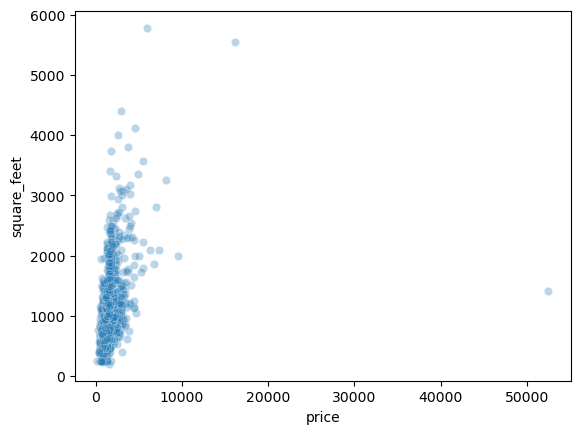

In [13]:
sns.scatterplot(data=df, x="price", y="square_feet", alpha=0.3,)

In [14]:
df.describe()

,bathrooms,bedrooms,price,square_feet,latitude,longitude,square_feet_price
count,1572.000000,1572.000000,1572.000000,1572.000000,1572.000000,1572.000000,1572.000000
mean,1.470775,1.879912,1514.191580,1050.766419,38.273784,-92.430417,1.612197
std,0.569609,0.816408,1570.788477,532.807199,5.222729,16.584598,1.202920
min,1.000000,0.000000,200.000000,200.000000,21.315500,-158.022100,0.294872
25%,1.000000,1.250000,971.875000,746.625000,34.137075,-100.789850,1.029010
50%,1.333333,1.811655,1295.000000,917.583333,39.163894,-87.956069,1.378166
75%,1.833333,2.000000,1699.250000,1194.050000,41.876075,-79.943281,1.961946
max,5.500000,6.000000,52500.000000,5784.000000,61.594000,-70.191600,37.023977


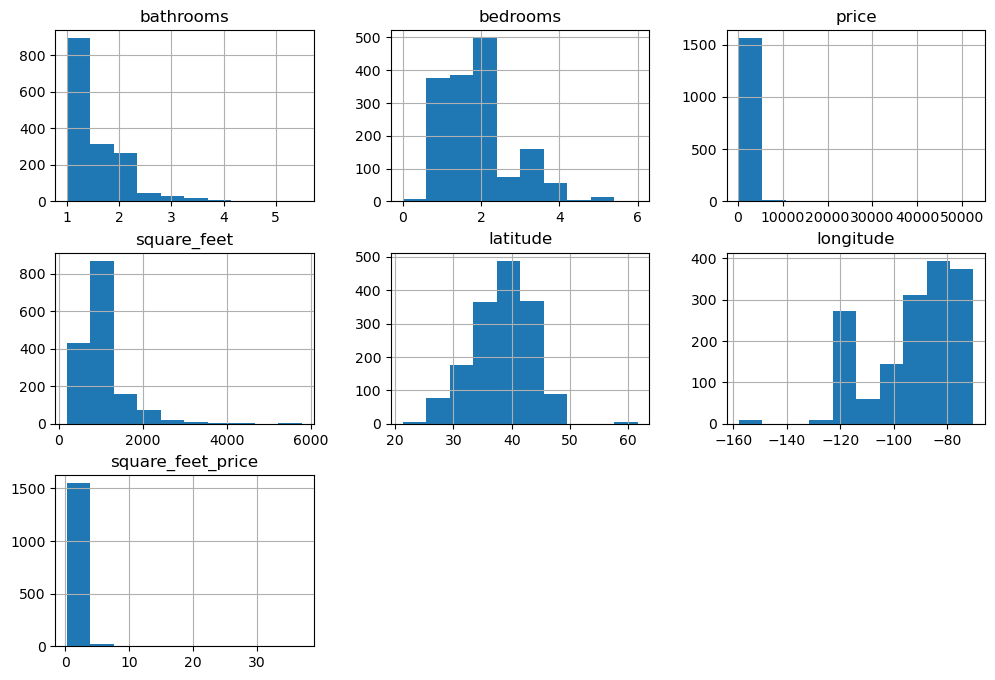

In [15]:
df.hist(figsize=(12,8))
plt.show()

In [16]:
from sklearn.preprocessing import StandardScaler

features = ["bedrooms", "bathrooms","price", "square_feet","square_feet_price"]

X = df[features].copy()

x_log= np.log1p(X[["price", "square_feet"]])

x_scaled = StandardScaler().fit_transform(x_log)                             
# To begin with applying 'Standard scaler' and 'Log'.
# I thought that "square feet" and "price" are needed to standardize and reduce skewness because of diffrence between two feautures. 

In [17]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, max_iter=3000, n_init=10, random_state=38)

y_kmeans = kmeans.fit_predict(x_scaled)

# specifying k=4 with n_initial= 10 (default) 
# Also k=3 specified however it was too crowded and does not show very much difference for "cluster-3". 

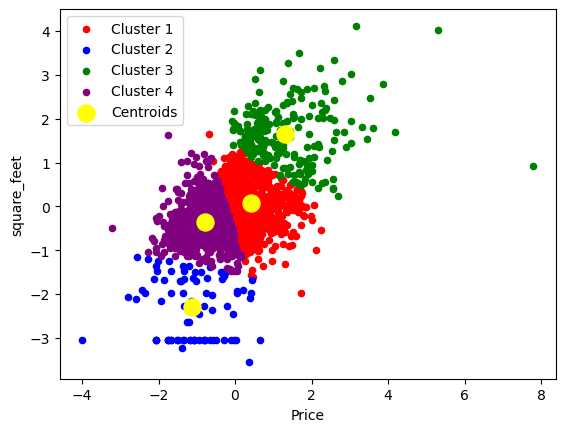

In [18]:
colors = ["red", "blue", "green","purple"]
for i in range(4):
    plt.scatter(x_scaled[y_kmeans == i, 0], x_scaled[y_kmeans == i, 1], s=20, c=colors[i], label=f"Cluster {i+1}")
# Get i applied the code which we have taught in class but it gave an error that says "tuckle(2)". 
#I was helped for this piece of code by gen AI.


plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:,1], s = 150, c = 'yellow', label = 'Centroids',)
plt.xlabel('Price')
plt.ylabel('square_feet')


plt.legend( loc ="best") 

In [19]:
# Definig clusters 
#Cluseter1 (blue)- A small low-size
#Cluster 2 (purple) - A low- price mid-size
#Cluster 2 (red) - A mid –market group
#Cluster 3 (green) - A high-price large-size

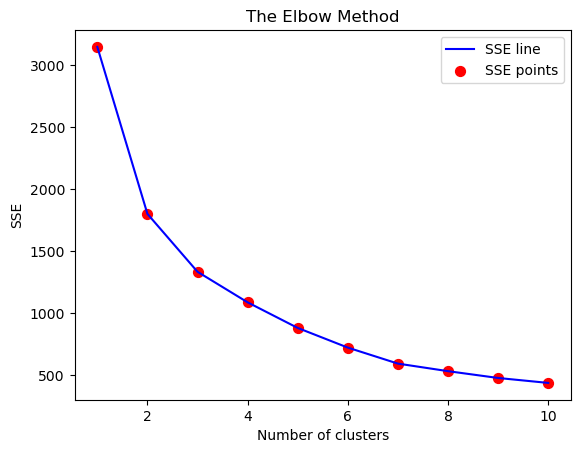

In [20]:
# Finding the optimum number of clusters for k-means classification
from sklearn.cluster import KMeans
sse = []   # Declare an array for the storage of values for Sum of Squares (SSE) Errors

# Set the loop from the minimum and maximum values
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, max_iter = 300, n_init = 10, random_state = 38)  # Initialise an object kmeans by calling 
                                                                                     # an object KMeans()
    kmeans.fit(x_scaled)                                                             # Training the model by calling fit() method
    sse.append(kmeans.inertia_)                                                      # Store kmeans.inertia_ in the array sse

# Plotting the results onto a line graph with points in a different color
plt.plot(range(1, 11), sse, linestyle = '-', color = 'blue', label = 'SSE line')
plt.scatter(range(1, 11), sse, color = 'red', marker = 'o', s = 50, label = 'SSE points')

plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')  
plt.legend()
plt.show()

In [21]:
# import silhouette score from sklearn library
from sklearn.metrics import silhouette_score

# Displaying the silhouette score values
print(f'Silhouette Score(n = 2|): {silhouette_score(x_scaled, y_kmeans)}')
print(f'Silhouette Score(n = 3|): {silhouette_score(x_scaled, y_kmeans)}')

Silhouette Score(n = 2|): 0.33833921125915867
Silhouette Score(n = 3|): 0.33833921125915867


In [22]:
from sklearn.metrics import silhouette_score


for n_clusters in range(2, 10):                                # Loop through cluster numbers from 2 to 9
    kmeans = KMeans(n_clusters = n_clusters, random_state = 42)
    labels = kmeans.fit_predict(df)                               
    score = silhouette_score(df, labels)
    print(f"Silhouette Score (n = {n_clusters}): {score:.4f}")

Silhouette Score (n = 2): 0.9789
Silhouette Score (n = 3): 0.6318
Silhouette Score (n = 4): 0.6101
Silhouette Score (n = 5): 0.4837
Silhouette Score (n = 6): 0.4890
Silhouette Score (n = 7): 0.4561
Silhouette Score (n = 8): 0.3804
Silhouette Score (n = 9): 0.3580


In [23]:
import scipy.cluster.hierarchy as sch

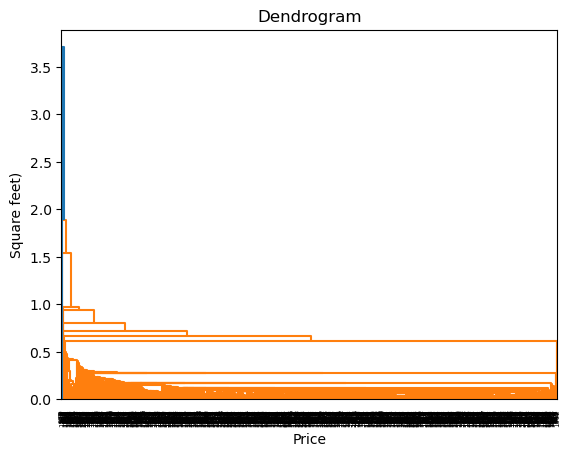

In [24]:
dendrogrm = sch.dendrogram(sch.linkage(x_scaled, method = 'single'))
plt.title('Dendrogram')
plt.xlabel('Price')
plt.ylabel('Square feet)')
plt.show()

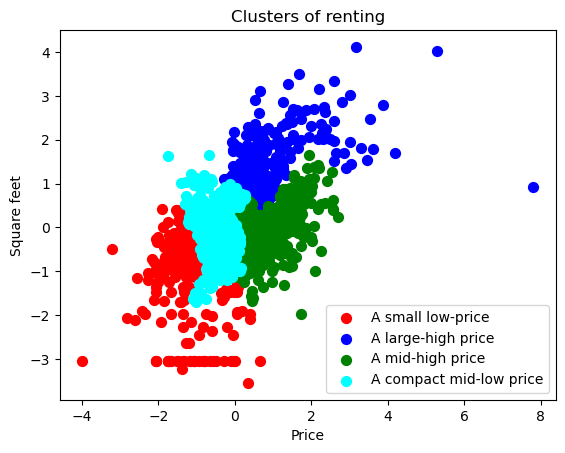

In [25]:
from sklearn.cluster import AgglomerativeClustering


hc = AgglomerativeClustering(n_clusters = 4, metric = 'euclidean', linkage = 'ward')
#  "hc" by calling a method 'AgglomerativeClustering'

y_hc = hc.fit_predict(x_scaled)


plt.scatter(x_scaled[y_hc == 0, 0], x_scaled[y_hc == 0, 1], s = 50, c = 'red', label = 'A small low-price')
plt.scatter(x_scaled[y_hc == 1, 0], x_scaled[y_hc == 1, 1], s = 50, c = 'blue', label = 'A large-high price')
plt.scatter(x_scaled[y_hc == 2, 0], x_scaled[y_hc == 2, 1], s = 50, c = 'green', label = 'A mid-high price ')
plt.scatter(x_scaled[y_hc == 3, 0], x_scaled[y_hc == 3, 1], s = 50, c = 'cyan', label = 'A compact mid-low price')


plt.title('Clusters of renting')
plt.xlabel('Price')
plt.ylabel('Square feet')
plt.legend()
plt.show()



In [26]:
from sklearn.cluster import DBSCAN
# Create an object using dbscan
dbscan = DBSCAN()

# Train the model by calling fit() method
# We take epsilon is 0.5, and min_samples or minPoints is 5. Let’s visualize the results from this model
dbscan.fit(df[['price', 'square_feet']])

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.5
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [27]:
# Add another column into the dataframe (df)
df['DBSCAN_labels'] = dbscan.labels_ 

# Display the dataframe records
df.head()

,bathrooms,bedrooms,price,square_feet,latitude,longitude,square_feet_price,DBSCAN_labels
cityname,,,,,,,,
Aberdeen,1.0,1.500000,1240.000000,1038.000000,39.5109,-76.1855,1.211298,-1
Abilene,1.0,1.333333,781.666667,717.833333,32.4418,-99.7494,1.093952,-1
Abingdon,1.5,2.000000,1120.000000,844.000000,39.4733,-76.2993,1.327014,-1
Abington,2.0,2.000000,1988.000000,1261.000000,42.1173,-70.9547,1.576527,-1
Absecon,2.0,2.000000,1276.666667,1175.000000,39.4432,-74.5117,1.086525,-1


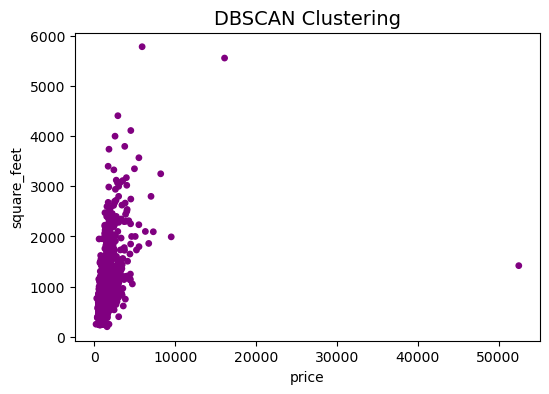

In [28]:
# Plotting resulting clusters
# Create an array colors
colors = ['purple','red','blue',]

import matplotlib
# Set the size of the figure

plt.figure(figsize = (6, 4))
plt.scatter(df['price'], df['square_feet'], c = df['DBSCAN_labels'], cmap = matplotlib.colors.ListedColormap(colors), s = 15)
plt.title('DBSCAN Clustering',fontsize = 14)
plt.xlabel('price', fontsize = 10)
plt.ylabel('square_feet', fontsize = 10)
plt.show()

In [29]:
from sklearn.neighbors import NearestNeighbors

# Initialise an object neigh by calling a method NearestNeighbors()
neigh = NearestNeighbors(n_neighbors = 2)

# Train the model by calling a method fit()
nbrs = neigh.fit(df[['price', 'square_feet']])

# Store the distance and indices into distances and indices arrays
distances, indices = nbrs.kneighbors(df[['price', 'square_feet']])

print(distances, indices)

[[ 0.         11.40175425]
 [ 0.          5.52016505]
 [ 0.          5.3638854 ]
 ...
 [ 0.         29.28215232]
 [ 0.         17.15938357]
 [ 0.         10.33485326]] [[   0  716]
 [   1  336]
 [   2  363]
 ...
 [1569 1543]
 [1570  993]
 [1571  741]]


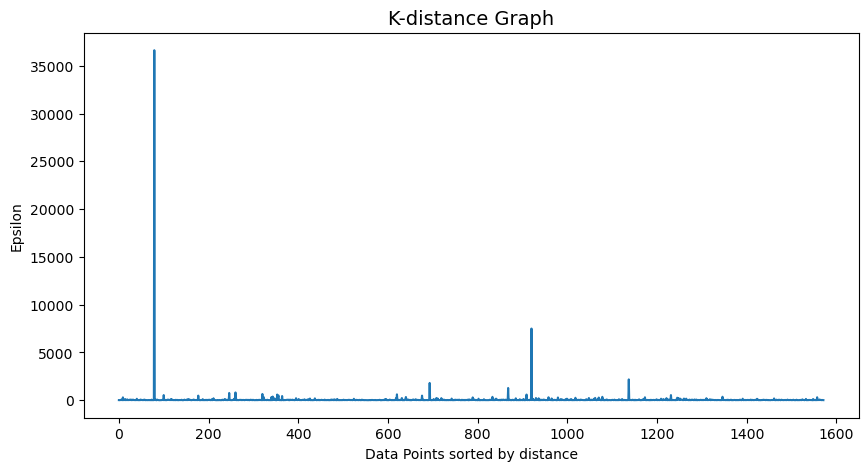

In [30]:
# Plotting K-distance Graph
# distances = np.sort(distances, axis=0)
distances = distances[:, 1]
plt.figure(figsize = (10, 5))
plt.plot(distances)
plt.title('K-distance Graph', fontsize = 14)
plt.xlabel('Data Points sorted by distance', fontsize = 10)
plt.ylabel('Epsilon', fontsize = 10)
plt.show()

In [31]:
dbscan_opt = DBSCAN(eps = 100, min_samples = 5)
# Initialise an object by calling a method DBSCAN along with parameters as eps and min_samples

dbscan_opt.fit(df[['price', 'square_feet']])

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",100
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [32]:
df['DBSCAN_opt_labels'] = dbscan_opt.labels_
df['DBSCAN_opt_labels'].value_counts()
# additinal column with "DBSCAN opt labels" and displaying them 

DBSCAN_opt_labels
 0    1299
-1     192
 1      48
 2       7
 4       6
 5       6
 6       5
 7       5
 3       4
Name: count, dtype: int64

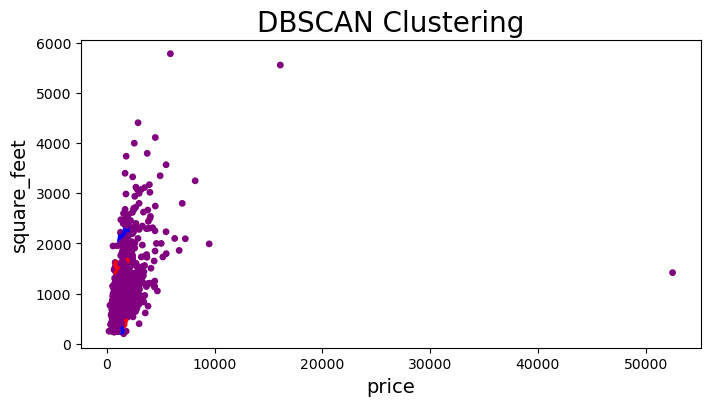

In [33]:
plt.figure(figsize = (8, 4))
plt.scatter(df['price'], df['square_feet'], c = df['DBSCAN_opt_labels'], cmap = matplotlib.colors.ListedColormap(colors), s = 15)
plt.title('DBSCAN Clustering', fontsize = 20)
plt.xlabel('price', fontsize = 14)
plt.ylabel('square_feet', fontsize = 14)
plt.show()

# Plotting the resulting clusters